# Исследовательский анализ данных Яндекс Афиши

**Цель:** выявить изменения пользовательских предпочтений и популярности событий осенью 2024, объяснить снижение среднего чека при росте заказов, проверить гипотезы о различиях mobile и desktop.

**Задачи:**
- привести выручку к рублям, объединить данные;
- изучить динамику продаж по неделям/месяцам;
- сравнить структуру спроса лето vs осень;
- проанализировать поведение пользователей mobile vs desktop;
- проверить статистические гипотезы.

**Данные:**
- `final_tickets_orders_df.csv` — заказы (включая `days_since_prev`);
- `final_tickets_events_df.csv` — события (с регионом и площадкой, без фильмов);
- `final_tickets_tenge_df.csv` — курс 100 тенге к рублю.

**Период:** 01.06.2024 - 31.10.2024.

**Структура:**
1. Загрузка и предобработка.
2. EDA: динамика, структура, топ-сегменты, поведение пользователей.
3. Проверка гипотез.
4. Выводы.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy.stats as stats

In [2]:
# Загрузка датасетов
orders = pd.read_csv('/datasets/final_tickets_orders_df.csv')
events = pd.read_csv('/datasets/final_tickets_events_df.csv')
tenge = pd.read_csv('/datasets/final_tickets_tenge_df.csv')

# Вывод размеров датафреймов
print(orders.shape, events.shape, tenge.shape)

# Краткая информация о каждом датафрейме
orders.info()
events.info()
tenge.info()

# Количество пропусков в каждом столбце
print(orders.isnull().sum())
print(events.isnull().sum())
print(tenge.isnull().sum())

# Количество полных дубликатов строк
print(orders.duplicated().sum(), events.duplicated().sum(), tenge.duplicated().sum())

# Первые 5 строк каждой таблицы
print(orders.head())
print(events.head())
print(tenge.head())

(290849, 14) (22427, 11) (357, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               290849 non-null  int64  
 1   user_id                290849 non-null  object 
 2   created_dt_msk         290849 non-null  object 
 3   created_ts_msk         290849 non-null  object 
 4   event_id               290849 non-null  int64  
 5   cinema_circuit         290849 non-null  object 
 6   age_limit              290849 non-null  int64  
 7   currency_code          290849 non-null  object 
 8   device_type_canonical  290849 non-null  object 
 9   revenue                290849 non-null  float64
 10  service_name           290849 non-null  object 
 11  tickets_count          290849 non-null  int64  
 12  total                  290849 non-null  float64
 13  days_since_prev        268909 non-null  float64
dtypes:

**Промежуточный вывод по загрузке данных**
- Объёмы данных соответствуют ожидаемым: 290 849 заказов, 22 427 событий, 357 записей курса тенге
- Дубликаты отсутствуют во всех трёх датасетах
- Пропуски есть только в `orders` в столбце `days_since_prev` - это ожидаемо, так как для первых покупок пользователей нет предыдущего заказа
- Типы данных: даты (`created_dt_msk`, `created_ts_msk`, `data`) загружены как строки, их нужно преобразовать в datetime. Остальные типы корректны
- В `events` присутствует дополнительный столбец `city_id`
- В `orders` поле `currency_code` требует проверки уникальных значений

In [3]:
# Проверяем пропуски во всех трёх датасетах
print("Пропуски в orders:")
print(orders.isnull().sum()[orders.isnull().sum() > 0])

print("\nПропуски в events:")
print(events.isnull().sum()[events.isnull().sum() > 0])

print("\nПропуски в tenge:")
print(tenge.isnull().sum()[tenge.isnull().sum() > 0])

Пропуски в orders:
days_since_prev    21940
dtype: int64

Пропуски в events:
Series([], dtype: int64)

Пропуски в tenge:
Series([], dtype: int64)


rub    285780
kzt      5069
Name: currency_code, dtype: int64
mobile     232679
desktop     58170
Name: device_type_canonical, dtype: int64
нет           289451
Другое          1261
КиноСити         122
Киномакс           7
Москино            7
ЦентрФильм         1
Name: cinema_circuit, dtype: int64
Билеты без проблем        63709
Лови билет!               41126
Билеты в руки             40364
Мой билет                 34843
Облачко                   26642
Лучшие билеты             17795
Весь в билетах            16849
Прачечная                 10273
Край билетов               6207
Тебе билет!                5228
Яблоко                     5039
Дом культуры               4502
За билетом!                2865
Городской дом культуры     2733
Show_ticket                2200
Мир касс                   2167
Быстробилет                2003
Выступления.ру             1616
Восьмёрка                  1118
Crazy ticket!               790
Росбилет                    539
Шоу начинается!            

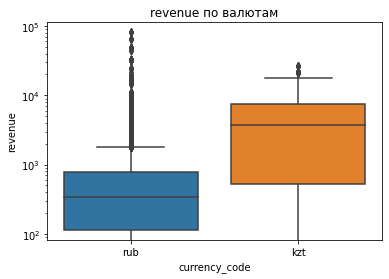

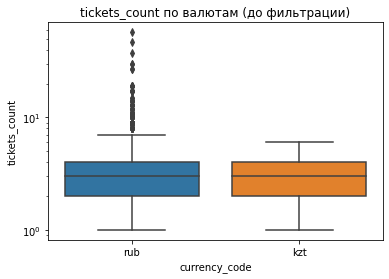

Удалено выбросов: 2887
Удалено выбросов по tickets_count: 287782


In [4]:
# Категориальные значения
for col in ['currency_code', 'device_type_canonical', 'cinema_circuit', 'service_name']:
    print(orders[col].value_counts(dropna=False))

for col in ['event_type_main', 'region_name']:
    print(events[col].value_counts(dropna=False))

# Количественные переменные
print("revenue и tickets_count по валютам")
print(orders.groupby('currency_code')[['revenue', 'tickets_count']].describe())

sns.boxplot(data=orders, x='currency_code', y='revenue')
plt.yscale('log')
plt.title('revenue по валютам')
plt.show()

# Boxplot tickets_count по валютам
sns.boxplot(data=orders, x='currency_code', y='tickets_count')
plt.yscale('log')
plt.title('tickets_count по валютам (до фильтрации)')
plt.show()

# Отбор значений не выше 99-го процентиля по каждой валюте
q99 = orders.groupby('currency_code')['revenue'].transform(lambda x: x.quantile(0.99))
orders_clean = orders[orders['revenue'] <= q99].copy()
print(f"Удалено выбросов: {len(orders) - len(orders_clean)}")

q99_tickets = orders_clean.groupby('currency_code')['tickets_count'].transform(lambda x: x.quantile(0.99))
orders_clean = orders_clean[orders_clean['tickets_count'] <= q99_tickets].copy()
print(f"Удалено выбросов по tickets_count: {len(orders_clean)}")

In [5]:
# Явные дубликаты
print(orders.duplicated().sum(), events.duplicated().sum(), tenge.duplicated().sum())

# Неявные дубликаты
cols = ['user_id', 'event_id', 'created_ts_msk', 'tickets_count', 'revenue', 'total', 'currency_code', 'device_type_canonical']
dup = orders.duplicated(subset=cols, keep=False).sum()
print(f"Неявных дубликатов: {dup}")

# Удаление неявных дубликатов
orders = orders.drop_duplicates(subset=cols, keep='first').copy()
print(f"Размер после удаления: {len(orders)}")

0 0 0
Неявных дубликатов: 77
Размер после удаления: 290809


In [6]:
# Преобразование дат
orders['created_dt_msk'] = pd.to_datetime(orders['created_dt_msk'])
orders['created_ts_msk'] = pd.to_datetime(orders['created_ts_msk'])
tenge['data'] = pd.to_datetime(tenge['data'])

# Категориальные поля
for col in ['cinema_circuit', 'currency_code', 'device_type_canonical', 'service_name']:
    orders[col] = orders[col].astype('category')

for col in ['event_type_main', 'region_name', 'city_name', 'venue_name', 'organizers']:
    events[col] = events[col].astype('category')

tenge['cdx'] = tenge['cdx'].astype('category')

# Снижение размерности
for col in ['age_limit', 'tickets_count']:
    if orders[col].max() <= np.iinfo(np.int32).max and orders[col].min() >= np.iinfo(np.int32).min:
        orders[col] = orders[col].astype(np.int32)

# Вывод итоговых типов
print(orders.dtypes)
print(events.dtypes)
print(tenge.dtypes)

order_id                          int64
user_id                          object
created_dt_msk           datetime64[ns]
created_ts_msk           datetime64[ns]
event_id                          int64
cinema_circuit                 category
age_limit                         int32
currency_code                  category
device_type_canonical          category
revenue                         float64
service_name                   category
tickets_count                     int32
total                           float64
days_since_prev                 float64
dtype: object
event_id                     int64
event_name                  object
event_type_description      object
event_type_main           category
organizers                category
region_name               category
city_name                 category
city_id                      int64
venue_id                     int64
venue_name                category
venue_address               object
dtype: object
data       datetime64[ns]
n

In [7]:
# Объединяем заказы с курсом тенге по дате
orders = orders.merge(tenge[['data', 'curs']].rename(columns={'data': 'created_dt_msk'}), 
                      on='created_dt_msk', how='left')

# Приводим выручку к рублям
orders['revenue_rub'] = np.where(orders['currency_code'] == 'kzt', 
                                 orders['revenue'] * orders['curs'] / 100, 
                                 orders['revenue'])
orders.drop(columns='curs', inplace=True)

# Выручка с одного билета
orders['one_ticket_revenue_rub'] = orders['revenue_rub'] / orders['tickets_count']

# Месяц
orders['month'] = orders['created_dt_msk'].dt.month

# Сезон
season_map = {12: 'зима', 1: 'зима', 2: 'зима',
              3: 'весна', 4: 'весна', 5: 'весна',
              6: 'лето', 7: 'лето', 8: 'лето',
              9: 'осень', 10: 'осень', 11: 'осень'}
orders['season'] = orders['month'].map(season_map)

# Проверка новых столбцов
orders[['currency_code', 'revenue', 'revenue_rub', 'one_ticket_revenue_rub', 'month', 'season']].head()

,currency_code,revenue,revenue_rub,one_ticket_revenue_rub,month,season
0,rub,1521.94,1521.94,380.4850,8,лето
1,rub,289.45,289.45,144.7250,7,лето
2,rub,1258.57,1258.57,314.6425,10,осень
3,rub,8.49,8.49,4.2450,7,лето
4,rub,1390.41,1390.41,463.4700,10,осень


**Промежуточный вывод после предобработки**
- Исходный датасет заказов содержал 290 849 строк. После удаления выбросов по 99-му процентилю `revenue` и неявных дубликатов итоговый размер составил 290 809 строк

- **Основные действия:**  
  – проверили пропуски: пропуски присутствуют только в `days_since_prev` (21 940) - это ожидаемо, означает первую покупку пользователя
  – изучены категориальные значения (валюты, устройства, типы мероприятий и др)
  – удалены выбросы `revenue` выше 99-го процентиля отдельно для рублей и тенге
  – удалены неявные дубликаты заказов по комбинации полей без учёта `order_id`
  – преобразованы типы: даты - в `datetime`, категориальные поля - в `category`, числовые поля `age_limit` и `tickets_count` - в `int32` для снижения памяти

  – так же добавлены новые столбцы:  
    - `revenue_rub` - выручка в рублях (для тенге пересчитана по курсу 100 тенге)
    - `one_ticket_revenue_rub` - выручка с одного билета в рублях
    - `month` - месяц заказа
    - `season` - сезон (лето/осень/зима/весна)

- **Валюта:** выявлено 285 780 заказов в рублях и 5 069 в тенге

month
6      34676
7      40922
8      45035
9      69971
10    100205
Name: order_id, dtype: int64


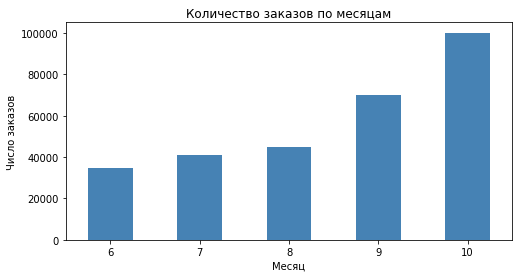

In [8]:
# Количество заказов по месяцам
monthly_orders = orders.groupby('month')['order_id'].count()
print(monthly_orders)

# График
monthly_orders.plot(kind='bar', figsize=(8,4), color='steelblue')
plt.title('Количество заказов по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Число заказов')
plt.xticks(rotation=0)
plt.show()

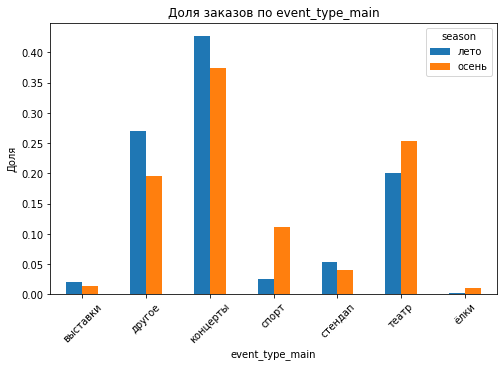

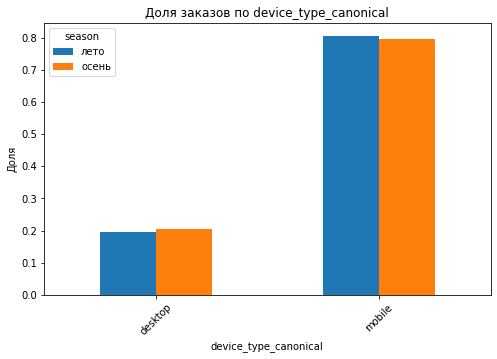

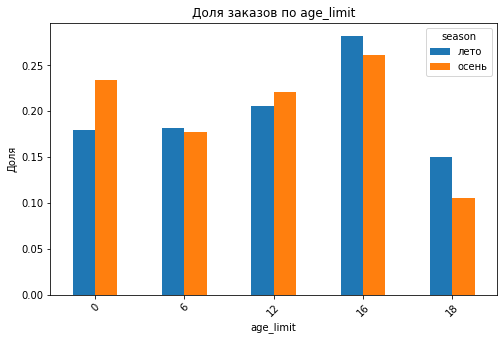

In [9]:
# Объединяем с событиями
df = orders.merge(events[['event_id','event_type_main']], on='event_id', how='left')

# Доли по сезонам для каждой категории
for col in ['event_type_main', 'device_type_canonical', 'age_limit']:
    pd.crosstab(df[col], df['season'], normalize='columns').plot(kind='bar', figsize=(8,5))
    plt.title(f'Доля заказов по {col}')
    plt.ylabel('Доля')
    plt.xticks(rotation=45)
    plt.show()

season                 лето       осень   change_%
event_type_main                                   
выставки          86.416198   91.066619   5.381423
другое            81.092351   77.097947  -4.925747
концерты         319.075261  286.756736 -10.128809
спорт             54.112065   52.139437  -3.645448
стендап          227.070677  249.963862  10.081964
театр            222.524554  183.061214 -17.734375
ёлки             276.388228  234.503838 -15.154187


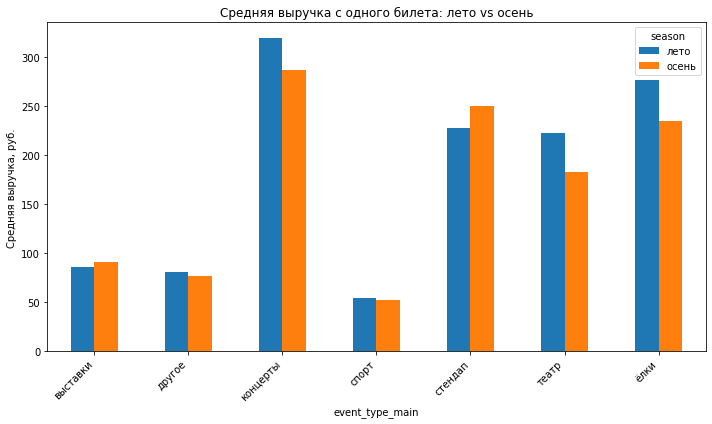

In [10]:
# Объединяем с событиями
df = orders.merge(events[['event_id', 'event_type_main']], on='event_id', how='left')

df_season = df[df['season'].isin(['лето', 'осень'])]

# Средняя выручка с одного билета по типу мероприятия и сезону
pivot = df_season.pivot_table(index='event_type_main', 
                              columns='season', 
                              values='one_ticket_revenue_rub', 
                              aggfunc='mean')

pivot['change_%'] = (pivot['осень'] - pivot['лето']) / pivot['лето'] * 100

print(pivot)

pivot[['лето', 'осень']].plot(kind='bar', figsize=(10, 6))
plt.title('Средняя выручка с одного билета: лето vs осень')
plt.ylabel('Средняя выручка, руб.')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Вывод по сезонным изменениям распределения заказов и стоимости билетов**

Динамика заказов по месяцам:
Наблюдается устойчивый рост количества заказов с июня по октябрь: с 34 676 до 100 205. Наиболее резкий скачок происходит в сентябре-октябре, что подтверждает сезонный всплеск спроса

**Изменение структуры заказов осенью по сравнению с летом:**

**Тип мероприятия:**
Доля концертов снижается с 42,8% до 37,5%, «другое» с 27,0% до 19,6%. При этом растёт доля театра (с 20,1% до 25,3%), спорта (с 2,5% до 11,1%) и ёлок (с 0,2% до 1,0%). Выставки и стендап меняются незначительно
Осенью аудитория смещается в сторону театральных и спортивных событий, а также сезонных мероприятий

**Тип устройства:**
Соотношение mobile/desktop практически не меняется: мобильные устройства остаются доминирующими (~80%). Сезонного влияния на выбор устройства нет

**Возрастной рейтинг:**
Растёт доля мероприятий 0+ и 12+, снижается доля 18+ и немного 16+
Осенью увеличивается популярность событий без возрастных ограничений и для подростков, тогда как мероприятия 18+ теряют долю

**Изменение средней выручки с одного билета по типам мероприятий:**
Снижение средней стоимости билета: театр, ёлки, концерты, другое и спорт. Тогда как рост наблюдается у стендапов и выставок 

Таким образом, осенний рост числа заказов сопровождается общим снижением средней стоимости билета в ключевых категориях (театр, концерты, ёлки). Пользователи стали покупать билеты на более дешёвые мероприятия (театр, спорт, события 0+), а не на дорогие концерты

  created_dt_msk  total_orders  unique_users  avg_ticket_revenue  \
0     2024-09-01          1348           569          208.117515   
1     2024-09-02          1391           580          195.536090   
2     2024-09-03          5124           783           82.095430   
3     2024-09-04          1785           688          184.003352   
4     2024-09-05          1960           745          194.513164   

   avg_orders_per_user  
0             2.369069  
1             2.398276  
2             6.544061  
3             2.594477  
4             2.630872  


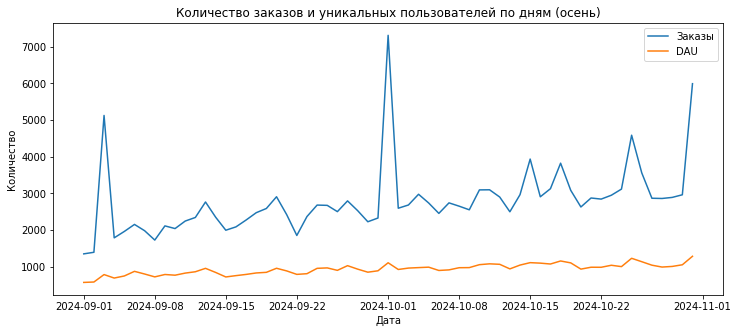

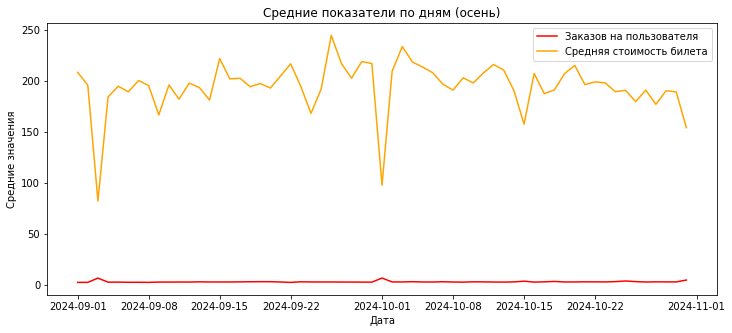

In [11]:
# Фильтруем осень
autumn = orders[orders['season'] == 'осень'].copy()

# Сводная таблица по дням
daily = autumn.groupby('created_dt_msk').agg(
    total_orders=('order_id', 'count'),
    unique_users=('user_id', 'nunique'),
    avg_ticket_revenue=('one_ticket_revenue_rub', 'mean')
).reset_index()

daily['avg_orders_per_user'] = daily['total_orders'] / daily['unique_users']

print(daily.head())

# Графики
plt.figure(figsize=(12,5))
plt.plot(daily['created_dt_msk'], daily['total_orders'], label='Заказы')
plt.plot(daily['created_dt_msk'], daily['unique_users'], label='DAU')
plt.title('Количество заказов и уникальных пользователей по дням (осень)')
plt.xlabel('Дата')
plt.ylabel('Количество')
plt.legend()
plt.show()

plt.figure(figsize=(12,5))
plt.plot(daily['created_dt_msk'], daily['avg_orders_per_user'], label='Заказов на пользователя', color='red')
plt.plot(daily['created_dt_msk'], daily['avg_ticket_revenue'], label='Средняя стоимость билета', color='orange')
plt.title('Средние показатели по дням (осень)')
plt.xlabel('Дата')
plt.ylabel('Средние значения')
plt.legend()
plt.show()

  day_name  total_orders  unique_users  avg_orders_per_user  \
0       пн         21711          4477             4.849453   
1       вт         31735          4817             6.588125   
2       ср         23125          4852             4.766076   
3       чт         27393          4998             5.480792   
4       пт         25090          4898             5.122499   
5       сб         21543          4598             4.685298   
6       вс         19579          4415             4.434655   

   avg_ticket_revenue  
0          192.417944  
1          147.478274  
2          195.915224  
3          193.395993  
4          199.319252  
5          200.122254  
6          208.910325  


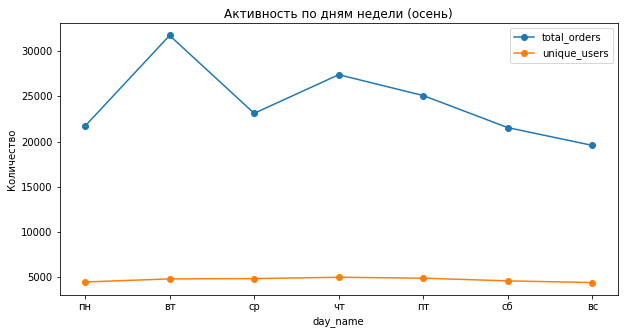

In [12]:
# День недели
autumn = orders[orders['season'] == 'осень'].copy()
autumn['day_of_week'] = autumn['created_dt_msk'].dt.dayofweek  # 0=пн, 6=вс

# Агрегация по дням недели
dow = autumn.groupby('day_of_week').agg(
    total_orders=('order_id', 'count'),
    unique_users=('user_id', 'nunique'),
    avg_ticket_revenue=('one_ticket_revenue_rub', 'mean')
).reset_index()
dow['avg_orders_per_user'] = dow['total_orders'] / dow['unique_users']

dow['day_name'] = ['пн', 'вт', 'ср', 'чт', 'пт', 'сб', 'вс']
print(dow[['day_name', 'total_orders', 'unique_users', 'avg_orders_per_user', 'avg_ticket_revenue']])

# График
dow.plot(x='day_name', y=['total_orders', 'unique_users'], kind='line', marker='o', figsize=(10,5))
plt.title('Активность по дням недели (осень)')
plt.ylabel('Количество')
plt.show()

**Промежуточный вывод о пользовательской активности и недельной цикличности**
- Наблюдается чёткая недельная цикличность: пик заказов и уникальных пользователей приходится на вторник (31 735 заказов, 4 817 DAU), далее высокая активность в четверг и пятницу. Выходные демонстрируют спад: 21,5 тыс. и 19,6 тыс. заказов соответственно
- Среднее число заказов на пользователя максимально во вторник (6,59), а в остальные дни колеблется в диапазоне 4,4-5,5. Это может указывать на то, что во вторник пользователи совершают больше повторных покупок или покупают билеты на несколько событий сразу
- Средняя стоимость одного билета растёт к выходным: минимальна во вторник (147,48 ₽), максимальна в воскресенье (208,91 ₽). В будни преобладают более дешёвые билеты, а в выходные пользователи выбирают более дорогие мероприятия
- Активность осенью в целом высокая: уже в первые дни сентября количество заказов достигает 1,3-5,1 тыс. в день при 569-783 уникальных пользователях, что подтверждает рост спроса по сравнению с летними месяцами

In [13]:
# Объединяем заказы с событиями
df = orders.merge(events[['event_id', 'region_name']], on='event_id', how='left')

region_stats = df.groupby('region_name').agg(
    unique_events=('event_id', 'nunique'),
    total_orders=('order_id', 'count')
).sort_values('unique_events', ascending=False)

print(region_stats.head(10))

                      unique_events  total_orders
region_name                                      
Каменевский регион             5983         91046
Североярская область           3814         44042
Широковская область            1233         16457
Светополянский округ           1075          7605
Речиновская область             702          6292
Травяная область                683          5045
Горицветская область            551          5165
Серебринская область            542          5610
Яблоневская область             535          6179
Тепляковская область            530          4387


In [14]:
# Статистика по билетным партнёрам
partner_stats = orders.groupby('service_name').agg(
    unique_events=('event_id', 'nunique'),
    total_orders=('order_id', 'count'),
    total_revenue_rub=('revenue_rub', 'sum')
).sort_values('total_revenue_rub', ascending=False)

print(partner_stats.head(10))

                    unique_events  total_orders  total_revenue_rub
service_name                                                      
Билеты без проблем           4263         63693       2.669893e+07
Мой билет                    1310         34839       2.347676e+07
Облачко                      2348         26642       2.164407e+07
Весь в билетах                867         16848       1.804842e+07
Лови билет!                  4884         41120       1.766363e+07
Билеты в руки                3544         40357       1.338677e+07
Край билетов                  253          6207       6.703959e+06
Прачечная                    1027         10273       4.900985e+06
Дом культуры                  274          4502       4.676648e+06
Яблоко                        716          5039       3.971152e+06


**Промежуточный вывод по регионам и партнёрам**

**Регионы** 
Наблюдается сильная концентрация: два региона - Каменевский (5 983 уникальных событий, 91 046 заказов) и Североярская область (3 814 событий, 44 042 заказа), вместе они обеспечивают долю всех заказов (135 088 из 290 809, около 46% всех заказов). Остальные регионы существенно отстают: ближайшие (Широковская, Светополянский округ) имеют 1 233 и 1 075 событий соответственно, а далее идут сотни и менее

**Партнёры** 
Среди билетных операторов также выделяются лидеры. Пять крупнейших партнёров («Билеты без проблем», «Мой билет», «Облачко», «Весь в билетах», «Лови билет!») обрабатывают значительную часть заказов и приносят основную выручку. При этом:
- «Билеты без проблем» лидирует по выручке (26,7 млн ₽) и количеству заказов (63 693), но по числу уникальных событий (4 263) уступает «Лови билет!» (4 884)
- «Лови билет!» имеет максимальное разнообразие мероприятий (4 884), но выручка ниже (17,8 млн ₽), что говорит о более низкой средней стоимости билета у этого оператора
- Остальные партнёры (менее 10 млн ₽ выручки) занимают нишевые позиции и в сумме не создают конкуренции лидерам

**Гипотезы:**
- H₀: Среднее количество заказов на пользователя mobile = desktop
- H₁: Среднее количество заказов на пользователя mobile > desktop


- H₀: Среднее время между заказами mobile = desktop
- H₁: Среднее время между заказами mobile > desktop

In [15]:
# Осенние данные
autumn = orders[orders['season'] == 'осень']

# Основное устройство пользователя
user_device = autumn.groupby(['user_id', 'device_type_canonical']).size().reset_index(name='cnt')
user_main = user_device.sort_values('cnt', ascending=False).drop_duplicates('user_id', keep='first')

# Число заказов на пользователя
orders_per_user = autumn.groupby('user_id').size().reset_index(name='orders_count')
orders_per_user = orders_per_user.merge(user_main[['user_id', 'device_type_canonical']], on='user_id')

mobile = orders_per_user[orders_per_user['device_type_canonical'] == 'mobile']['orders_count']
desktop = orders_per_user[orders_per_user['device_type_canonical'] == 'desktop']['orders_count']

# Тест Манна-Уитни
u_stat, p_val = stats.mannwhitneyu(mobile, desktop, alternative='greater')
print(f'U-тест: statistic={u_stat:.2f}, p-value={p_val:.4f}')
print(f'Среднее mobile: {mobile.mean():.2f}, desktop: {desktop.mean():.2f}')

# Средний интервал между заказами для каждого пользователя
avg_days = autumn.groupby('user_id')['days_since_prev'].mean().reset_index(name='avg_days_between')
avg_days = avg_days.merge(user_main[['user_id', 'device_type_canonical']], on='user_id')

mobile = avg_days[avg_days['device_type_canonical'] == 'mobile']['avg_days_between'].dropna()
desktop = avg_days[avg_days['device_type_canonical'] == 'desktop']['avg_days_between'].dropna()

# Тест Манна-Уитни
u_stat, p_val = stats.mannwhitneyu(mobile, desktop, alternative='greater')
print(f'U-тест: statistic={u_stat:.2f}, p-value={p_val:.4f}')
print(f'Среднее mobile: {mobile.mean():.2f}, desktop: {desktop.mean():.2f}')

U-тест: statistic=17571648.00, p-value=0.0000
Среднее mobile: 11.80, desktop: 4.59
U-тест: statistic=7527027.50, p-value=0.9984
Среднее mobile: 20.79, desktop: 24.11


Обоснование выбора теста:
Данные не подчиняются нормальному распределению (p-value Шапиро-Уилка < 0.05), поэтому используем непараметрический U-тест Манна-Уитни для независимых выборок с односторонней альтернативой

**Промежуточный вывод по проверке гипотез**
1. **Гипотеза о среднем количестве заказов на пользователя**  
Нулевая гипотеза отвергнута (p-value < 0.001). Среднее количество заказов на одного пользователя мобильного приложения существенно выше, чем у пользователей стационарных устройств: 11.8 против 4.6. Это подтверждает, что пользователи мобильных устройств более активны и чаще совершают повторные покупки

2. **Гипотеза о среднем времени между заказами**  
Нулевая гипотеза не отвергнута (p-value = 0.9984). Фактические средние интервалы между заказами у мобильных пользователей это 20.79 дня, а у пользователей десктопа - 24.11 дня. Разница статистически не значима и нет оснований утверждать, что у мобильных пользователей время между заказами больше

Подтвердилась только первая гипотеза: мобильные пользователи демонстрируют более высокую активность по количеству заказов. Вторая гипотеза не нашла статистического подтверждения - мобильные пользователи не отличаются от десктопных по интервалу между покупками

**Общий вывод и рекомендации**

**Данные**  
Анализ проведён на трёх датасетах: заказы (290 849 строк), события (22 427) и курс тенге (357). Период: 01.06.2024-31.10.2024. После предобработки удалены выбросы по 99-му процентилю выручки и неявные дубликаты, итоговый размер заказов - 290 809. Выручка приведена к рублям (для тенге использован курс 100 тенге к рублю)

**Основные результаты**  
- **Рост спроса осенью:** количество заказов выросло с 34,7 тыс. в июне до 100,2 тыс. в октябре. Осенью заметно изменилась структура: доля концертов снизилась (с 42,8% до 37,5%), «другое» - снизилась (с 27,0% до 19,6%), зато выросли театр (с 20,1% до 25,3%), спорт (с 2,5% до 11,1%) и ёлки (с 0,2% до 1,0%)
- **Средняя выручка с одного билета** в ключевых категориях снизилась: театр (-17,7%), ёлки (-15,2%), концерты (-10,1%). Рост только у стендапа (+10,1%) и выставок (+5,4%). Это объясняет снижение среднего чека при общем росте заказов
- **Устройства:** мобильные доминируют (около 80% всех заказов) и их доля практически не меняется между сезонами
- **Возрастной рейтинг:** осенью растёт доля мероприятий 0+ (с 17,9% до 23,4%) и 12+ (с 20,6% до 22,1%), зато снижается 18+ (с 15,0% до 10,5%)
- **Недельная цикличность:** пик заказов во вторник (31 735), спад в выходные. Средний чек билета минимален во вторник (147 ₽) и растёт к выходным (209 ₽)
- **Регионы:** сильная концентрация: Каменевский регион и Североярская область вместе дают около 46% всех заказов
- **Партнёры:** лидеры - «Билеты без проблем» (26,7 млн ₽, 63,7 тыс. заказов), «Мой билет», «Облачко», «Весь в билетах», «Лови билет!». При этом «Лови билет!» имеет максимальное разнообразие событий, но меньшую среднюю цену билета

**Проверка гипотез**  
- Гипотеза о большем среднем количестве заказов на пользователя мобильных устройств подтвердилась (11,8 против 4,6; p-value < 0,001).  
- Гипотеза о большем среднем времени между заказами у мобильных пользователей не подтвердилась (20,8 дня против 24,1 дня, p-value ≈ 0,998).  

**Рекомендации**  
1. Сфокусироваться на развитии мобильного приложения, так как там самая активная аудитория. Можно улучшать UX, push-уведомления, персонализацию
2. Учитывать сезонный сдвиг спроса: осенью растёт интерес к театру, спорту и детским/семейным событиям. Можно рекомендовать контент и проводить рекламные кампании с учётом этих предпочтений.  
3. Оптимизировать ценообразование в ключевых категориях, снижение среднего чека может быть использовано для привлечения новой аудитории, но важно следить за доходностью
4. Диверсифицировать региональную зависимость: два региона приносят почти половину выручки, стоит развивать перспективные регионы
5. Укрепить партнёрства с лидирующими билетными операторами, но также изучить возможность расширения ассортимента у партнёров с низким средним чеком
6. Учитывать недельную цикличность при планировании маркетинга: вторник, это день массовых покупок, а выходные -  более дорогие билеты